# 信赖域与狗腿法

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

LM通过给步长加惩罚来限制移动。信赖域则直接规定“这次最多走多远”：在$\|h\|\le\Delta$内最小化局部模型。两者共享同一个核心判断——局部模型能否预测真实下降。

## 两个容易计算的候选步

GN步$h_{\rm GN}$给出线性残差模型的最优解；沿负梯度方向最小化同一个模型，得到Cauchy步

$$h_{\rm C}=-\frac{g^Tg}{\|Jg\|^2}g.$$

狗腿法沿折线$0\to h_{\rm C}\to h_{\rm GN}$找信赖域内的点：

1. GN步在球内，直接使用。
2. Cauchy步也在球外，沿负梯度截到球面。
3. 否则，取$h_{\rm C}+\beta(h_{\rm GN}-h_{\rm C})$与球面的交点。

第三种情况令$v=h_{\rm GN}-h_{\rm C}$，解

$$\|v\|^2\beta^2+2h_{\rm C}^Tv\,\beta+\|h_{\rm C}\|^2-\Delta^2=0,$$

选$0\le\beta\le1$的根。这个构造是对信赖域子问题的近似求解，不是精确解的通用公式。

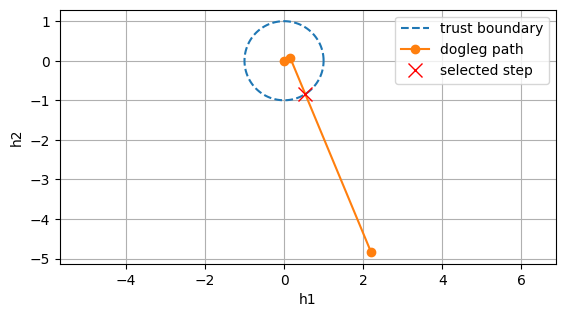

In [2]:
x = np.array([-1.2,1.])
r = np.array([10*(x[1]-x[0]**2),1-x[0]])
J = np.array([[-20*x[0],10.],[-1.,0.]])
g = J.T@r
hc = -(g@g)/((J@g)@(J@g))*g
hgn = np.linalg.lstsq(J,-r,rcond=None)[0]
radius = 1.; v = hgn-hc
a,b,c = v@v,2*hc@v,hc@hc-radius**2
beta = (-b+np.sqrt(b*b-4*a*c))/(2*a)
h = hc+beta*v
assert 0 <= beta <= 1
assert np.isclose(np.linalg.norm(h),radius)
theta = np.linspace(0,2*np.pi,200)
plt.plot(radius*np.cos(theta),radius*np.sin(theta),'--',label='trust boundary')
plt.plot([0,hc[0],hgn[0]],[0,hc[1],hgn[1]],'o-',label='dogleg path')
plt.plot(*h,'rx',markersize=10,label='selected step')
plt.axis('equal');plt.xlabel('h1');plt.ylabel('h2');plt.legend();plt.show()

## 半径如何调整

与LM一样，计算真实下降/预测下降的$\rho$。本书实现中，$\rho<0.25$时半径缩为四分之一；$\rho>0.75$且步接近边界时扩大半径；$\rho>0.1$才接受更新。这些是具体实现选择，不是唯一允许的阈值。

如果一个很小的步在球内，模型仍很差，继续扩大半径通常没有意义。反之，如果步一直顶到边界而预测很准确，扩大信赖域能加快进展。

GN [1. 1.] gradient attempts: 10
LM [1. 1.] gradient attempts: 17
dogleg [1. 1.] gradient attempts: 14


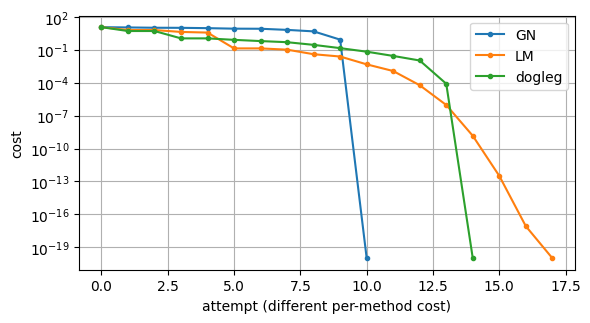

In [3]:
def fun(x):
    return np.array([10*(x[1]-x[0]**2),1-x[0]])
def jac(x):
    return np.array([[-20*x[0],10.],[-1.,0.]])
results = {
    'GN':gauss_newton(fun,jac,[-1.2,1.]),
    'LM':levenberg_marquardt(fun,jac,[-1.2,1.]),
    'dogleg':dogleg(fun,jac,[-1.2,1.])
}
for name,result in results.items():
    print(name,result.x,result.status,'attempts:',len(result.history)-1)
    plt.semilogy([max(p['cost'],1e-20) for p in result.history],'.-',label=name)
    assert np.allclose(result.x,[1,1],atol=1e-5)
plt.xlabel('attempt (different per-method cost)');plt.ylabel('cost')
plt.legend();plt.show()

图中的尝试次数不能直接当作运行时间对比：三种方法每步的函数/雅可比求值和线性代数开销并不完全相同。做性能研究应在相同停止精度下统计实际求值与耗时。

原参考书狗腿算法有已记录的符号疑点。这里始终从$q(0)-q(h)=-g^Th-\tfrac12\|Jh\|^2$计算预测下降，避免把针对特殊分支的表达式未经核验搬到一般非零残差问题。

## 练习与解答

练习：将初始半径缩小100倍，早期步长和迭代次数如何变化？解答：初期更谨慎，通常需要几次半径扩大才进入快速区域；具体总次数仍取决于模型。

练习：SciPy的dogbox是否就是这里的球形狗腿法？解答：不是；dogbox使用矩形信赖域并处理边界，名称相近但不能按同一算法解释。